In [1]:
# ============================================================
# STEP 1: SETUP, IMPORTS, AND REPRODUCIBILITY
# ============================================================

# Import Python libraries.
import random
import re
import math
import numpy as np
import matplotlib.pyplot as plt

# Import PyTorch libraries.
import torch
import torch.nn as nn
import torch.nn.functional as F


# ============================================================
# PERSONAL PARAMETERS
# ============================================================

# Personal parameters derived from SID4.
SID4 = 1980
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10


# ============================================================
# REPRODUCIBILITY
# ============================================================

# Set random seeds so that the experiment can be reproduced.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)


# ============================================================
# DEVICE
# ============================================================

# Q2 uses a very small dataset and model, so CPU is sufficient.
device = torch.device("cpu")


# ============================================================
# DISPLAY CONFIGURATION
# ============================================================

print("Q2 SETUP")
print("-" * 50)
print("SID4   :", SID4)
print("SEED   :", SEED)
print("SLICE  :", SLICE)
print("HP_ID  :", HP_ID)
print("CLS_A  :", CLS_A)
print("CLS_B  :", CLS_B)
print("Device :", device)
print("-" * 50)
print("Setup completed successfully.")

Q2 SETUP
--------------------------------------------------
SID4   : 1980
SEED   : 1980
SLICE  : 980
HP_ID  : 0
CLS_A  : 0
CLS_B  : 1
Device : cpu
--------------------------------------------------
Setup completed successfully.


In [2]:
# ============================================================
# STEP 2: LOAD THE Q2 DATASET
# ============================================================

# This is the exact text provided in the assignment.
# We will use it for tokenization and next-token prediction.

text = """
Neural networks are powerful models for learning representations from data.
They consist of layers of interconnected neurons.
Attention mechanisms allow models to focus on relevant parts of the input.
Transformers rely entirely on attention instead of recurrence.
Autoregressive models generate text one token at a time.
"""

# Remove unnecessary spaces/newlines from the beginning and end.
text = text.strip()


# ============================================================
# DISPLAY THE DATASET
# ============================================================

print("Q2 DATASET")
print("-" * 60)
print(text)

Q2 DATASET
------------------------------------------------------------
Neural networks are powerful models for learning representations from data.
They consist of layers of interconnected neurons.
Attention mechanisms allow models to focus on relevant parts of the input.
Transformers rely entirely on attention instead of recurrence.
Autoregressive models generate text one token at a time.


In [3]:
# ============================================================
# STEP 3: WORD-LEVEL TOKENIZATION AND VOCABULARY CREATION
# ============================================================

# Convert the text to lowercase so that words such as
# "Neural" and "neural" would be treated as the same token.
text_lower = text.lower()


# ============================================================
# WORD-LEVEL TOKENIZATION
# ============================================================

# Extract words and punctuation as separate tokens.
# Example:
# "models from data." -> ["models", "from", "data", "."]
tokens = re.findall(r"\b\w+\b|[^\w\s]", text_lower)


# ============================================================
# CREATE VOCABULARY
# ============================================================

# Create a sorted list containing each unique token only once.
vocab = sorted(set(tokens))

# Number of unique tokens in the dataset.
vocab_size = len(vocab)


# ============================================================
# CREATE TOKEN-ID MAPPINGS
# ============================================================

# Map every token to a unique integer ID.
word_to_id = {word: idx for idx, word in enumerate(vocab)}

# Reverse mapping: integer ID back to its token.
id_to_word = {idx: word for word, idx in word_to_id.items()}


# ============================================================
# DISPLAY RESULTS
# ============================================================

print("WORD-LEVEL TOKENIZATION")
print("-" * 60)

print("Total number of tokens :", len(tokens))
print("Vocabulary size        :", vocab_size)

print("\nTokens:")
print(tokens)

print("\nVocabulary:")
print(vocab)

print("\nSample Token-to-ID Mapping:")
for word in vocab[:10]:
    print(f"{word:<20} -> {word_to_id[word]}")

WORD-LEVEL TOKENIZATION
------------------------------------------------------------
Total number of tokens : 51
Vocabulary size        : 40

Tokens:
['neural', 'networks', 'are', 'powerful', 'models', 'for', 'learning', 'representations', 'from', 'data', '.', 'they', 'consist', 'of', 'layers', 'of', 'interconnected', 'neurons', '.', 'attention', 'mechanisms', 'allow', 'models', 'to', 'focus', 'on', 'relevant', 'parts', 'of', 'the', 'input', '.', 'transformers', 'rely', 'entirely', 'on', 'attention', 'instead', 'of', 'recurrence', '.', 'autoregressive', 'models', 'generate', 'text', 'one', 'token', 'at', 'a', 'time', '.']

Vocabulary:
['.', 'a', 'allow', 'are', 'at', 'attention', 'autoregressive', 'consist', 'data', 'entirely', 'focus', 'for', 'from', 'generate', 'input', 'instead', 'interconnected', 'layers', 'learning', 'mechanisms', 'models', 'networks', 'neural', 'neurons', 'of', 'on', 'one', 'parts', 'powerful', 'recurrence', 'relevant', 'rely', 'representations', 'text', 'the', '

In [4]:
# ============================================================
# STEP 4: CONVERT TOKENS TO IDS AND CREATE NEXT-TOKEN DATA
# ============================================================

# Convert every token in the dataset into its integer ID.
token_ids = [word_to_id[token] for token in tokens]


# ============================================================
# CREATE INPUT AND TARGET SEQUENCES
# ============================================================

# For next-token prediction:
# input  = all tokens except the last token
# target = all tokens except the first token
#
# Example:
# Tokens: [A, B, C, D]
# Input : [A, B, C]
# Target: [B, C, D]

input_ids = token_ids[:-1]
target_ids = token_ids[1:]


# ============================================================
# CONVERT TO PYTORCH TENSORS
# ============================================================

# Convert the Python lists into PyTorch tensors.
input_tensor = torch.tensor(input_ids, dtype=torch.long, device=device)
target_tensor = torch.tensor(target_ids, dtype=torch.long, device=device)


# ============================================================
# DISPLAY RESULTS
# ============================================================

print("NEXT-TOKEN TRAINING DATA")
print("-" * 60)

print("Number of input tokens :", len(input_tensor))
print("Number of target tokens:", len(target_tensor))

print("\nFirst 10 input token IDs:")
print(input_tensor[:10])

print("\nFirst 10 target token IDs:")
print(target_tensor[:10])

print("\nFirst 10 input-target token pairs:")
for i in range(min(10, len(input_tensor))):
    input_word = id_to_word[input_tensor[i].item()]
    target_word = id_to_word[target_tensor[i].item()]

    print(f"{input_word:<20} -> {target_word}")

NEXT-TOKEN TRAINING DATA
------------------------------------------------------------
Number of input tokens : 50
Number of target tokens: 50

First 10 input token IDs:
tensor([22, 21,  3, 28, 20, 11, 18, 32, 12,  8])

First 10 target token IDs:
tensor([21,  3, 28, 20, 11, 18, 32, 12,  8,  0])

First 10 input-target token pairs:
neural               -> networks
networks             -> are
are                  -> powerful
powerful             -> models
models               -> for
for                  -> learning
learning             -> representations
representations      -> from
from                 -> data
data                 -> .


In [5]:
# ============================================================
# STEP 5: DEFINE SINGLE-HEAD SELF-ATTENTION MODEL FROM SCRATCH
# ============================================================

class SelfAttentionModel(nn.Module):
    def __init__(self, vocab_size, embed_dim=32):
        super().__init__()

        # ----------------------------------------------------
        # TRAINABLE WORD EMBEDDING
        # ----------------------------------------------------
        # Converts token IDs into dense vectors.
        self.embedding = nn.Embedding(vocab_size, embed_dim)

        # ----------------------------------------------------
        # QUERY, KEY, VALUE PROJECTIONS
        # ----------------------------------------------------
        # These layers learn the Q, K, and V representations
        # used in scaled dot-product self-attention.
        self.query = nn.Linear(embed_dim, embed_dim, bias=False)
        self.key = nn.Linear(embed_dim, embed_dim, bias=False)
        self.value = nn.Linear(embed_dim, embed_dim, bias=False)

        # ----------------------------------------------------
        # OUTPUT LAYER
        # ----------------------------------------------------
        # Converts the attention output into vocabulary logits
        # for next-token prediction.
        self.output = nn.Linear(embed_dim, vocab_size)

        # Save embedding dimension for scaling.
        self.embed_dim = embed_dim


    def forward(self, x):

        # ----------------------------------------------------
        # STEP 1: TOKEN EMBEDDINGS
        # ----------------------------------------------------
        embeddings = self.embedding(x)

        # ----------------------------------------------------
        # STEP 2: CREATE QUERY, KEY, VALUE
        # ----------------------------------------------------
        Q = self.query(embeddings)
        K = self.key(embeddings)
        V = self.value(embeddings)

        # ----------------------------------------------------
        # STEP 3: SCALED DOT-PRODUCT ATTENTION SCORES
        # ----------------------------------------------------
        # QK^T measures similarity between token positions.
        scores = torch.matmul(Q, K.transpose(-2, -1))

        # Scale by sqrt(d_k), as described in
        # "Attention Is All You Need".
        scores = scores / math.sqrt(self.embed_dim)

        # ----------------------------------------------------
        # STEP 4: SOFTMAX ATTENTION WEIGHTS
        # ----------------------------------------------------
        attention_weights = F.softmax(scores, dim=-1)

        # ----------------------------------------------------
        # STEP 5: WEIGHTED SUM OF VALUES
        # ----------------------------------------------------
        attention_output = torch.matmul(attention_weights, V)

        # ----------------------------------------------------
        # STEP 6: NEXT-TOKEN PREDICTION LOGITS
        # ----------------------------------------------------
        logits = self.output(attention_output)

        return logits, attention_weights

In [6]:
# ============================================================
# CREATE THE UNMASKED SELF-ATTENTION MODEL
#
#Part 1 = Unmasked self-attention → every token can attend to every token.

#Part 2 = Causal masked self-attention → each token can attend only to itself and previous tokens.
# ============================================================

embed_dim = 32

model_unmasked = SelfAttentionModel(
    vocab_size=vocab_size,
    embed_dim=embed_dim
).to(device)

print("Unmasked Self-Attention Model Created")
print("-" * 60)
print(model_unmasked)

Unmasked Self-Attention Model Created
------------------------------------------------------------
SelfAttentionModel(
  (embedding): Embedding(40, 32)
  (query): Linear(in_features=32, out_features=32, bias=False)
  (key): Linear(in_features=32, out_features=32, bias=False)
  (value): Linear(in_features=32, out_features=32, bias=False)
  (output): Linear(in_features=32, out_features=40, bias=True)
)


In [7]:
# ============================================================
# STEP 6: TRAIN THE UNMASKED SELF-ATTENTION MODEL
# ============================================================

# Cross-entropy loss is used for next-token classification.
criterion = nn.CrossEntropyLoss()

# Adam optimizer updates all trainable model parameters.
optimizer = torch.optim.Adam(
    model_unmasked.parameters(),
    lr=0.01
)

# Number of training epochs.
num_epochs = 500

# Store loss values so we can inspect training progress later.
unmasked_losses = []


# ============================================================
# TRAINING LOOP
# ============================================================

model_unmasked.train()

for epoch in range(num_epochs):

    # Clear gradients from the previous iteration.
    optimizer.zero_grad()

    # Forward pass through the unmasked attention model.
    logits, attention_weights = model_unmasked(input_tensor)

    # Compare predicted next tokens with the true next tokens.
    loss = criterion(logits, target_tensor)

    # Compute gradients.
    loss.backward()

    # Update model parameters.
    optimizer.step()

    # Save the current loss.
    unmasked_losses.append(loss.item())

    # Print progress every 100 epochs.
    if (epoch + 1) % 100 == 0:
        print(
            f"Epoch [{epoch + 1}/{num_epochs}] "
            f"Loss: {loss.item():.4f}"
        )


# ============================================================
# FINAL TRAINING LOSS
# ============================================================

print("-" * 60)
print(f"Final Unmasked Training Loss: {unmasked_losses[-1]:.4f}")

Epoch [100/500] Loss: 0.3468
Epoch [200/500] Loss: 0.3442
Epoch [300/500] Loss: 0.3437
Epoch [400/500] Loss: 0.3442
Epoch [500/500] Loss: 0.3436
------------------------------------------------------------
Final Unmasked Training Loss: 0.3436


In [8]:
# ============================================================
# STEP 7: COMPUTE FULL UNMASKED ATTENTION MATRIX
# ============================================================

# Convert the complete token sequence into a PyTorch tensor.
full_token_tensor = torch.tensor(
    token_ids,
    dtype=torch.long,
    device=device
)


# ============================================================
# RUN THE TRAINED MODEL
# ============================================================

# Switch the model to evaluation mode.
model_unmasked.eval()

# No gradients are needed because we are only inspecting
# the trained attention weights.
with torch.no_grad():

    # Pass the full sequence through the trained model.
    full_logits, unmasked_attention = model_unmasked(
        full_token_tensor
    )


# ============================================================
# DISPLAY ATTENTION MATRIX INFORMATION
# ============================================================

print("UNMASKED ATTENTION MATRIX")
print("-" * 60)

print("Total tokens          :", len(tokens))
print("Attention matrix shape:", unmasked_attention.shape)

print("\nFirst 5 x 5 section of attention matrix:")
print(unmasked_attention[:5, :5])


# ============================================================
# VERIFY ATTENTION WEIGHTS
# ============================================================

# Each row should sum to approximately 1 because
# softmax was applied across each row.
row_sums = unmasked_attention.sum(dim=-1)

print("\nFirst 5 row sums:")
print(row_sums[:5])

UNMASKED ATTENTION MATRIX
------------------------------------------------------------
Total tokens          : 51
Attention matrix shape: torch.Size([51, 51])

First 5 x 5 section of attention matrix:
tensor([[1.6364e-05, 9.4110e-08, 2.2761e-06, 3.6081e-08, 1.9121e-01],
        [9.3381e-07, 2.7800e-05, 6.7563e-05, 1.2274e-04, 1.8919e-06],
        [1.9305e-06, 4.0706e-04, 3.9345e-04, 8.0124e-04, 4.9952e-08],
        [4.6480e-06, 7.7343e-05, 8.8616e-04, 3.3921e-03, 7.4776e-04],
        [4.1518e-09, 3.1912e-11, 1.5177e-09, 2.7441e-12, 6.5249e-11]])

First 5 row sums:
tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


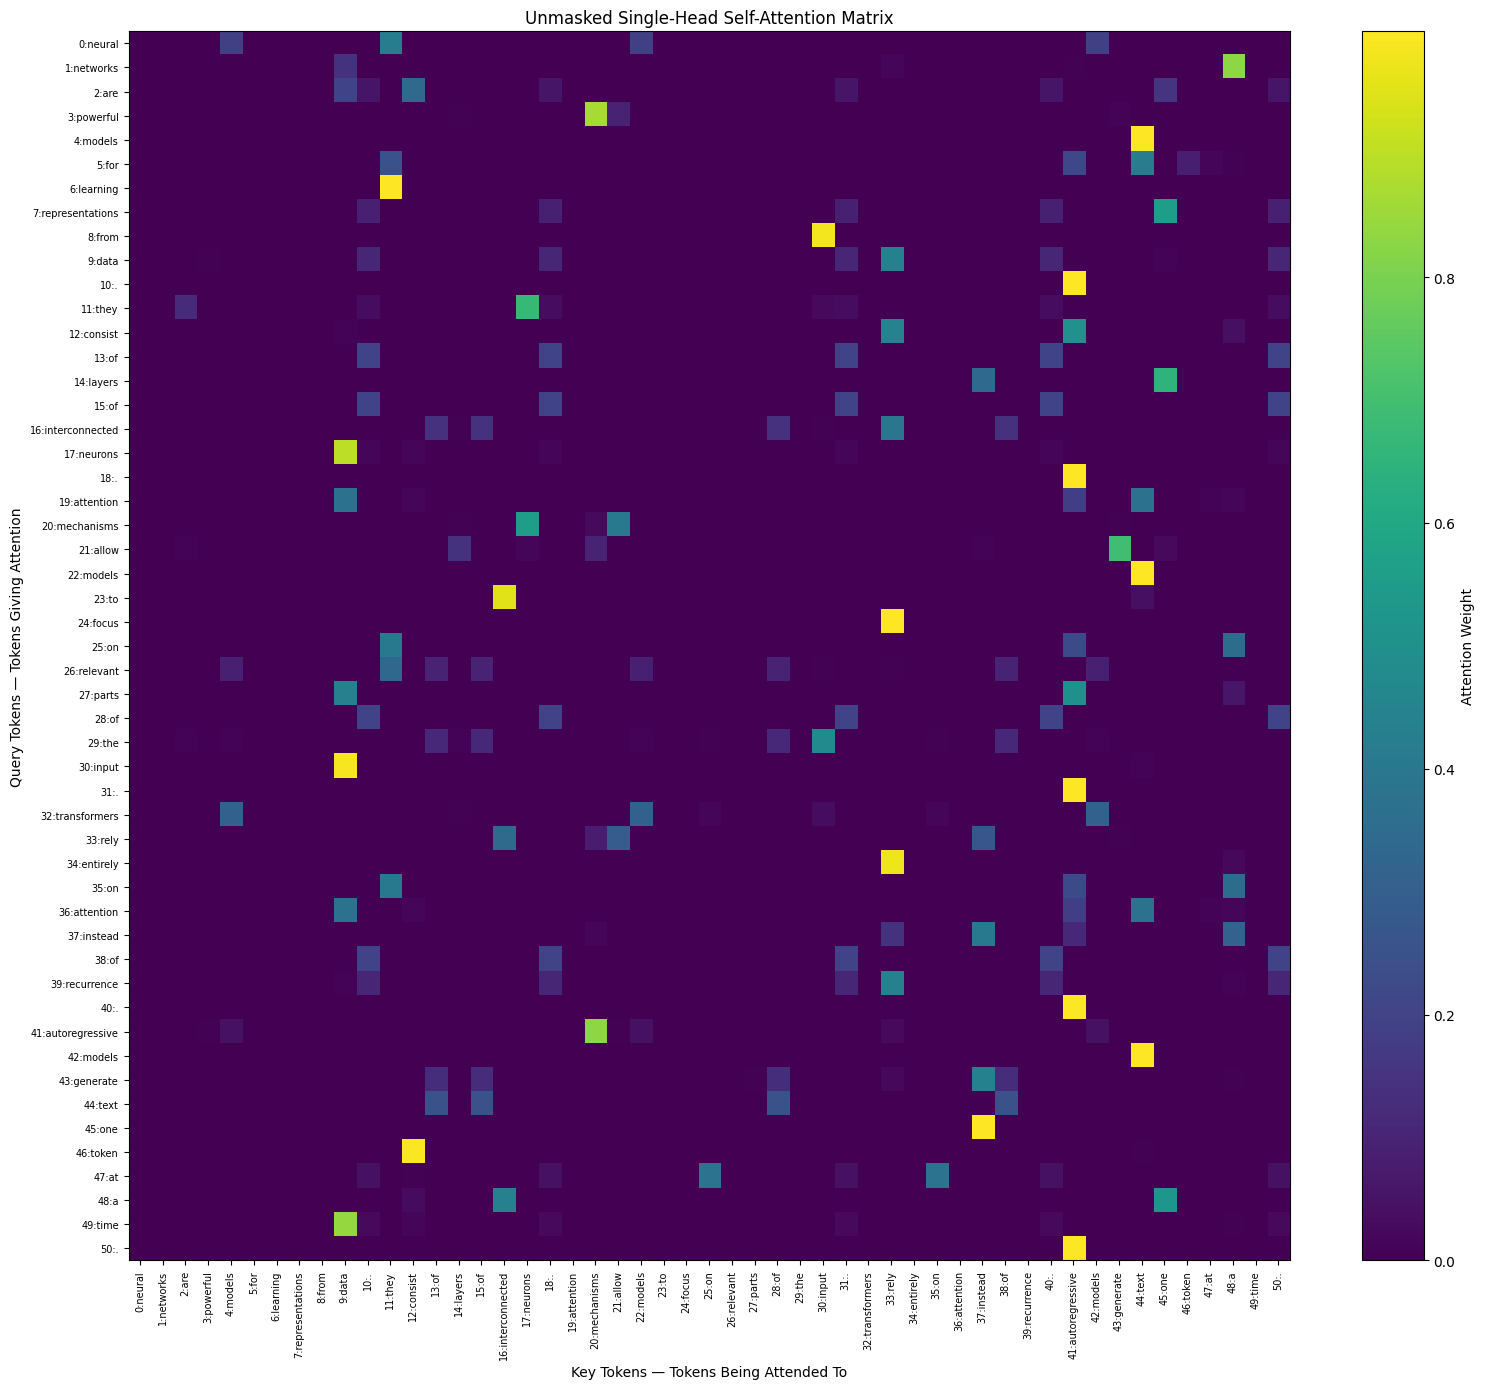

In [9]:
# ============================================================
# STEP 8: VISUALIZE UNMASKED ATTENTION HEATMAP
# ============================================================

# Convert the attention tensor to a NumPy array for plotting.
attention_matrix = unmasked_attention.cpu().numpy()


# ============================================================
# CREATE TOKEN LABELS
# ============================================================

# Add token positions so repeated words can be distinguished.
token_labels = [
    f"{i}:{token}"
    for i, token in enumerate(tokens)
]


# ============================================================
# PLOT THE HEATMAP
# ============================================================

plt.figure(figsize=(16, 14))

plt.imshow(
    attention_matrix,
    aspect="auto"
)

plt.colorbar(label="Attention Weight")

plt.xticks(
    range(len(token_labels)),
    token_labels,
    rotation=90,
    fontsize=7
)

plt.yticks(
    range(len(token_labels)),
    token_labels,
    fontsize=7
)

plt.xlabel("Key Tokens — Tokens Being Attended To")
plt.ylabel("Query Tokens — Tokens Giving Attention")

plt.title(
    "Unmasked Single-Head Self-Attention Matrix"
)

plt.tight_layout()

plt.show()

In [12]:
# ============================================================
# STEP 9: DEFINE CAUSAL MASKED SELF-ATTENTION MODEL
# ============================================================

class CausalSelfAttentionModel(nn.Module):

    def __init__(self, vocab_size, embed_dim=32):
        super().__init__()

        # ----------------------------------------------------
        # TRAINABLE WORD EMBEDDING
        # ----------------------------------------------------
        self.embedding = nn.Embedding(vocab_size, embed_dim)


        # ----------------------------------------------------
        # QUERY, KEY, VALUE PROJECTIONS
        # ----------------------------------------------------
        self.query = nn.Linear(embed_dim, embed_dim, bias=False)
        self.key = nn.Linear(embed_dim, embed_dim, bias=False)
        self.value = nn.Linear(embed_dim, embed_dim, bias=False)


        # ----------------------------------------------------
        # OUTPUT LAYER FOR NEXT-TOKEN PREDICTION
        # ----------------------------------------------------
        self.output = nn.Linear(embed_dim, vocab_size)

        self.embed_dim = embed_dim


    def forward(self, x):

        # ----------------------------------------------------
        # STEP 1: CREATE EMBEDDINGS
        # ----------------------------------------------------
        embeddings = self.embedding(x)


        # ----------------------------------------------------
        # STEP 2: CREATE QUERY, KEY, VALUE
        # ----------------------------------------------------
        Q = self.query(embeddings)
        K = self.key(embeddings)
        V = self.value(embeddings)


        # ----------------------------------------------------
        # STEP 3: SCALED DOT-PRODUCT ATTENTION SCORES
        # ----------------------------------------------------
        scores = torch.matmul(Q, K.transpose(-2, -1))

        scores = scores / math.sqrt(self.embed_dim)


        # ----------------------------------------------------
        # STEP 4: CREATE LOWER-TRIANGULAR CAUSAL MASK
        # ----------------------------------------------------
        sequence_length = x.size(0)

        causal_mask = torch.tril(
            torch.ones(
                sequence_length,
                sequence_length,
                device=x.device
            )
        ).bool()


        # ----------------------------------------------------
        # STEP 5: APPLY MASK BEFORE SOFTMAX
        # ----------------------------------------------------
        # Future positions are replaced with -infinity.
        # After softmax, their attention weights become 0.
        scores = scores.masked_fill(
            ~causal_mask,
            float("-inf")
        )


        # ----------------------------------------------------
        # STEP 6: COMPUTE ATTENTION WEIGHTS
        # ----------------------------------------------------
        attention_weights = F.softmax(scores, dim=-1)


        # ----------------------------------------------------
        # STEP 7: WEIGHTED SUM OF VALUES
        # ----------------------------------------------------
        attention_output = torch.matmul(
            attention_weights,
            V
        )


        # ----------------------------------------------------
        # STEP 8: NEXT-TOKEN LOGITS
        # ----------------------------------------------------
        logits = self.output(attention_output)

        return logits, attention_weights

In [13]:
# ============================================================
# STEP 9B: CREATE THE CAUSAL MASKED MODEL
# ============================================================

# Reset seed for reproducible initialization.
torch.manual_seed(SEED)

# Create the masked attention model.
model_masked = CausalSelfAttentionModel(
    vocab_size=vocab_size,
    embed_dim=embed_dim
).to(device)

# Display the model.
print("Causal Masked Self-Attention Model Created")
print("-" * 60)
print(model_masked)

Causal Masked Self-Attention Model Created
------------------------------------------------------------
CausalSelfAttentionModel(
  (embedding): Embedding(40, 32)
  (query): Linear(in_features=32, out_features=32, bias=False)
  (key): Linear(in_features=32, out_features=32, bias=False)
  (value): Linear(in_features=32, out_features=32, bias=False)
  (output): Linear(in_features=32, out_features=40, bias=True)
)


In [14]:
# ============================================================
# STEP 10: TRAIN THE CAUSAL MASKED SELF-ATTENTION MODEL
# ============================================================

# Cross-entropy loss for next-token prediction.
criterion_masked = nn.CrossEntropyLoss()

# Adam optimizer for the masked model.
optimizer_masked = torch.optim.Adam(
    model_masked.parameters(),
    lr=0.01
)

# Use the same number of epochs as the unmasked model
# so the comparison is fair.
num_epochs_masked = 500

# Store training losses.
masked_losses = []


# ============================================================
# TRAINING LOOP
# ============================================================

model_masked.train()

for epoch in range(num_epochs_masked):

    # Clear old gradients.
    optimizer_masked.zero_grad()

    # Forward pass through the causal masked model.
    logits_masked, attention_masked = model_masked(input_tensor)

    # Compute next-token prediction loss.
    loss_masked = criterion_masked(
        logits_masked,
        target_tensor
    )

    # Backpropagation.
    loss_masked.backward()

    # Update model parameters.
    optimizer_masked.step()

    # Store loss value.
    masked_losses.append(loss_masked.item())

    # Print progress every 100 epochs.
    if (epoch + 1) % 100 == 0:
        print(
            f"Epoch [{epoch + 1}/{num_epochs_masked}] "
            f"Loss: {loss_masked.item():.4f}"
        )


# ============================================================
# FINAL TRAINING LOSS
# ============================================================

print("-" * 60)
print(
    f"Final Causal Masked Training Loss: "
    f"{masked_losses[-1]:.4f}"
)

Epoch [100/500] Loss: 0.1959
Epoch [200/500] Loss: 0.1243
Epoch [300/500] Loss: 0.1390
Epoch [400/500] Loss: 0.1389
Epoch [500/500] Loss: 0.1387
------------------------------------------------------------
Final Causal Masked Training Loss: 0.1387


In [15]:
# ============================================================
# STEP 11: COMPUTE FULL CAUSAL MASKED ATTENTION MATRIX
# ============================================================

# Switch the masked model to evaluation mode.
model_masked.eval()

# No gradients are needed during evaluation.
with torch.no_grad():

    # Pass the complete token sequence through the masked model.
    full_logits_masked, masked_attention = model_masked(
        full_token_tensor
    )


# ============================================================
# DISPLAY MATRIX INFORMATION
# ============================================================

print("CAUSAL MASKED ATTENTION MATRIX")
print("-" * 60)

print("Total tokens          :", len(tokens))
print("Attention matrix shape:", masked_attention.shape)

print("\nFirst 5 x 5 section:")
print(masked_attention[:5, :5])


# ============================================================
# VERIFY ROW SUMS
# ============================================================

# Each row should still sum to approximately 1.
masked_row_sums = masked_attention.sum(dim=-1)

print("\nFirst 5 row sums:")
print(masked_row_sums[:5])


# ============================================================
# VERIFY FUTURE-TOKEN ATTENTION
# ============================================================

# Extract values above the main diagonal.
# These correspond to future-token attention.
future_attention = torch.triu(
    masked_attention,
    diagonal=1
)

print(
    "\nMaximum attention given to a future token:",
    future_attention.max().item()
)

CAUSAL MASKED ATTENTION MATRIX
------------------------------------------------------------
Total tokens          : 51
Attention matrix shape: torch.Size([51, 51])

First 5 x 5 section:
tensor([[1.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00],
        [8.3518e-03, 9.9165e-01, 0.0000e+00, 0.0000e+00, 0.0000e+00],
        [7.6610e-06, 5.0862e-04, 9.9948e-01, 0.0000e+00, 0.0000e+00],
        [3.0643e-01, 2.6794e-02, 8.1936e-03, 6.5859e-01, 0.0000e+00],
        [3.3175e-01, 1.3581e-02, 1.1751e-03, 6.7977e-04, 6.5282e-01]])

First 5 row sums:
tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000])

Maximum attention given to a future token: 0.0


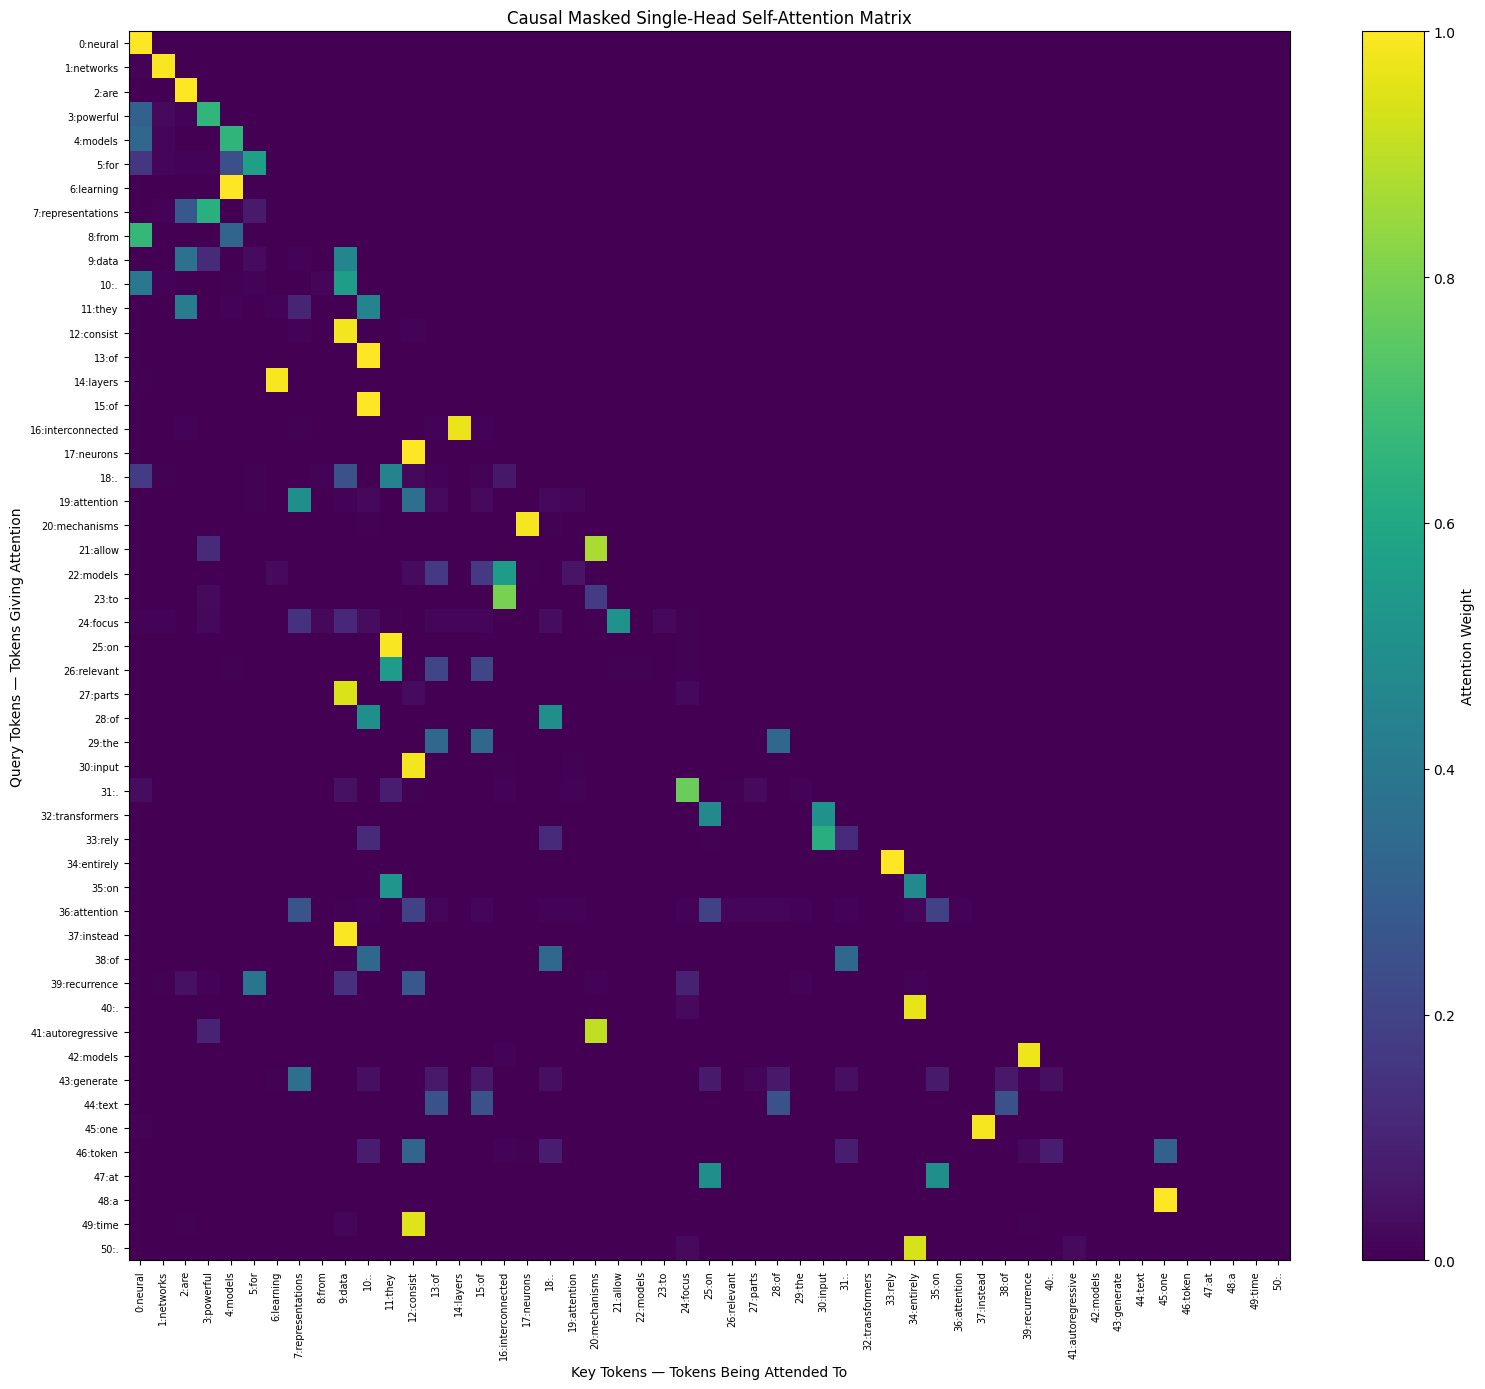

In [16]:
# ============================================================
# STEP 12: VISUALIZE CAUSAL MASKED ATTENTION HEATMAP
# ============================================================

# Convert attention tensor to NumPy for plotting.
masked_attention_matrix = masked_attention.cpu().numpy()


# ============================================================
# CREATE TOKEN LABELS
# ============================================================

token_labels = [
    f"{i}:{token}"
    for i, token in enumerate(tokens)
]


# ============================================================
# PLOT THE HEATMAP
# ============================================================

plt.figure(figsize=(16, 14))

plt.imshow(
    masked_attention_matrix,
    aspect="auto"
)

plt.colorbar(label="Attention Weight")

plt.xticks(
    range(len(token_labels)),
    token_labels,
    rotation=90,
    fontsize=7
)

plt.yticks(
    range(len(token_labels)),
    token_labels,
    fontsize=7
)

plt.xlabel("Key Tokens — Tokens Being Attended To")
plt.ylabel("Query Tokens — Tokens Giving Attention")

plt.title(
    "Causal Masked Single-Head Self-Attention Matrix"
)

plt.tight_layout()

plt.show()

In [17]:
# ============================================================
# STEP 13: COMPARE UNMASKED AND MASKED MODEL PERFORMANCE
# ============================================================

model_unmasked.eval()
model_masked.eval()

with torch.no_grad():

    # --------------------------------------------------------
    # UNMASKED MODEL PREDICTIONS
    # --------------------------------------------------------
    unmasked_logits, _ = model_unmasked(input_tensor)

    unmasked_predictions = torch.argmax(
        unmasked_logits,
        dim=-1
    )

    unmasked_accuracy = (
        unmasked_predictions == target_tensor
    ).float().mean().item()


    # --------------------------------------------------------
    # MASKED MODEL PREDICTIONS
    # --------------------------------------------------------
    masked_logits, _ = model_masked(input_tensor)

    masked_predictions = torch.argmax(
        masked_logits,
        dim=-1
    )

    masked_accuracy = (
        masked_predictions == target_tensor
    ).float().mean().item()


# ============================================================
# DISPLAY COMPARISON
# ============================================================

print("MODEL COMPARISON")
print("-" * 60)

print(f"Unmasked Final Loss   : {unmasked_losses[-1]:.4f}")
print(f"Unmasked Accuracy     : {unmasked_accuracy * 100:.2f}%")

print()

print(f"Masked Final Loss     : {masked_losses[-1]:.4f}")
print(f"Masked Accuracy       : {masked_accuracy * 100:.2f}%")

print()

print(
    "Maximum Future-Token Attention:",
    future_attention.max().item()
)

MODEL COMPARISON
------------------------------------------------------------
Unmasked Final Loss   : 0.3436
Unmasked Accuracy     : 80.00%

Masked Final Loss     : 0.1387
Masked Accuracy       : 94.00%

Maximum Future-Token Attention: 0.0


## Q2 Findings and Comparison

Using trainable word embeddings and distinct Query (Q), Key (K), and Value (V) projections, a single-head scaled .-product self-attention mechanism was created from the ground up. A next-token prediction objective was used to train both models for 500 epochs.

### Unmasked Self-Attention

Unmasked Self-Attention Every token in the sequence, including future tokens, was able to attend to every other token in the sequence thanks to the unmasked model. As a result, attention values above and below the main diagonal were present in the resulting attention heatmap. The model's next-token training accuracy was 80.00 percent, and its final training loss was 0.3436.

### Causal Masked Self-Attention

Prior to the softmax operation, the scaled attention scores for the causal model were subjected to a lower-triangular mask. As a result, tokens that appeared later in the sequence could not be attended to by each token. A lower-triangular structure was evident in the masked attention heatmap, with zero attention weights in the upper-right area. Additionally, the numerical verification confirmed that the causal mask was applied correctly by demonstrating that the **maximum attention assigned to any future token was 0.0**. The next-token training accuracy of **94.00 %** and the final training loss of **0.1387** were attained by the causal masked model.

### Comparison

| Model | Final Training Loss | Next-Token Training Accuracy | Future-Token Attention |
|---|---:|---:|---|
| Unmasked Self-Attention | 0.3436 | 80.00% | Allowed |
| Causal Masked Self-Attention | 0.1387 | 94.00% | Blocked (0.0) |

The causal masked model outperformed the unmasked model in this experiment in terms of training accuracy and training loss. This result does not, however, imply that causal masking always increases predictive accuracy; rather, it is particular to this small dataset and training setup. The primary distinction is structural: causal attention limits each position to itself and previous positions only, while **unmasked attention can use information from both past and future tokens. ** This limitation makes causal attention suitable for autoregressive next-token generation and stops future-information leakage.

In [18]:
# ============================================================
# STEP 15: CREATE METRICS.md
# ============================================================

metrics_content = f"""
# Homework 3 - Q2 Metrics

## Experiment Configuration
SID4: {SID4}
Seed: {SEED}
Device: {device}
Vocabulary Size: {vocab_size}
Total Tokens: {len(tokens)}
Embedding Dimension: {embed_dim}
Training Epochs: 500
Learning Rate: 0.01

## Unmasked Self-Attention
Final Training Loss: {unmasked_losses[-1]:.4f}
Next-Token Training Accuracy: {unmasked_accuracy * 100:.2f}%

## Causal Masked Self-Attention
Final Training Loss: {masked_losses[-1]:.4f}
Next-Token Training Accuracy: {masked_accuracy * 100:.2f}%
Maximum Future-Token Attention: {future_attention.max().item()}

## Attention Matrix
Unmasked Attention Shape: {tuple(unmasked_attention.shape)}
Masked Attention Shape: {tuple(masked_attention.shape)}
"""

# Save the metrics to a Markdown file.
with open("METRICS.md", "w") as f:
    f.write(metrics_content)

print("Created: METRICS.md")
print()
print(metrics_content)

Created: METRICS.md


# Homework 3 - Q2 Metrics

## Experiment Configuration
SID4: 1980
Seed: 1980
Device: cpu
Vocabulary Size: 40
Total Tokens: 51
Embedding Dimension: 32
Training Epochs: 500
Learning Rate: 0.01

## Unmasked Self-Attention
Final Training Loss: 0.3436
Next-Token Training Accuracy: 80.00%

## Causal Masked Self-Attention
Final Training Loss: 0.1387
Next-Token Training Accuracy: 94.00%
Maximum Future-Token Attention: 0.0

## Attention Matrix
Unmasked Attention Shape: (51, 51)
Masked Attention Shape: (51, 51)



In [19]:
# ============================================================
# STEP 16: CREATE RUN_LOG.txt
# ============================================================

run_log_content = f"""
Homework 3 - Q2 Run Log
------------------------------------------------------------

Notebook              : HW3_q2.ipynb
SID4                  : {SID4}
Seed                  : {SEED}
Device                : {device}

Total Tokens          : {len(tokens)}
Vocabulary Size       : {vocab_size}
Embedding Dimension   : {embed_dim}

Unmasked Model
--------------
Epochs                 : 500
Learning Rate          : 0.01
Final Loss             : {unmasked_losses[-1]:.4f}
Training Accuracy      : {unmasked_accuracy * 100:.2f}%

Causal Masked Model
-------------------
Epochs                 : 500
Learning Rate          : 0.01
Final Loss             : {masked_losses[-1]:.4f}
Training Accuracy      : {masked_accuracy * 100:.2f}%
Max Future Attention   : {future_attention.max().item()}

Attention Matrix Shape
----------------------
Unmasked               : {tuple(unmasked_attention.shape)}
Masked                 : {tuple(masked_attention.shape)}
"""

with open("RUN_LOG.txt", "w") as f:
    f.write(run_log_content)

print("Created: RUN_LOG.txt")
print()
print(run_log_content)

Created: RUN_LOG.txt


Homework 3 - Q2 Run Log
------------------------------------------------------------

Notebook              : HW3_q2.ipynb
SID4                  : 1980
Seed                  : 1980
Device                : cpu

Total Tokens          : 51
Vocabulary Size       : 40
Embedding Dimension   : 32

Unmasked Model
--------------
Epochs                 : 500
Learning Rate          : 0.01
Final Loss             : 0.3436
Training Accuracy      : 80.00%

Causal Masked Model
-------------------
Epochs                 : 500
Learning Rate          : 0.01
Final Loss             : 0.1387
Training Accuracy      : 94.00%
Max Future Attention   : 0.0

Attention Matrix Shape
----------------------
Unmasked               : (51, 51)
Masked                 : (51, 51)



In [20]:
# ============================================================
# STEP 17: CREATE AI_USE.md
# ============================================================

ai_use_content = """
# AI Use Disclosure - Homework 3

## How AI Assistance Was Used

AI assistance was used for:
- Structuring the notebook into clear experimental steps.
- Explaining self-attention, scaled dot-product attention, and causal masking.
- Drafting PyTorch code for the self-attention implementation.
- Debugging runtime errors.
- Interpreting the attention matrices and training results.
- Organizing the final findings and comparison.

## Specific Issue Identified and Corrected

During implementation, the training cell for the causal masked model initially failed with:

NameError: name 'model_masked' is not defined

The error occurred because the causal model class had been defined, but an instance of the model had not yet been created in the notebook runtime.

The issue was identified from the Python traceback. The solution was to explicitly create the model using:

model_masked = CausalSelfAttentionModel(
    vocab_size=vocab_size,
    embed_dim=embed_dim
).to(device)

After creating the model instance, the causal masked model trained successfully.

## Verification

All code was executed in the notebook and the outputs were checked manually.

The causal mask implementation was also numerically verified by checking the maximum attention assigned to future positions. The result was:

Maximum Future-Token Attention = 0.0

This confirmed that future-token attention was completely blocked.
"""

with open("AI_USE.md", "w") as f:
    f.write(ai_use_content)

print("Created: AI_USE.md")
print()
print(ai_use_content)

Created: AI_USE.md


# AI Use Disclosure - Homework 3

## How AI Assistance Was Used

AI assistance was used for:
- Structuring the notebook into clear experimental steps.
- Explaining self-attention, scaled dot-product attention, and causal masking.
- Drafting PyTorch code for the self-attention implementation.
- Debugging runtime errors.
- Interpreting the attention matrices and training results.
- Organizing the final findings and comparison.

## Specific Issue Identified and Corrected

During implementation, the training cell for the causal masked model initially failed with:

NameError: name 'model_masked' is not defined

The error occurred because the causal model class had been defined, but an instance of the model had not yet been created in the notebook runtime.

The issue was identified from the Python traceback. The solution was to explicitly create the model using:

model_masked = CausalSelfAttentionModel(
    vocab_size=vocab_size,
    embed_dim=embed_dim
).to(device)

Aft